# Problema 3 — Classificação de Qualidade de Vinhos Utilizando k-NN

A indústria vinícola depende historicamente de avaliações humanas — caras, lentas e subjetivas. Um modelo preditivo de qualidade tem aplicações diretas no controle de lotes antes do engarrafamento, na precificação e na certificação de denominação de origem por órgãos reguladores. Na pesquisa enológica (ciência que estuda a produção, conservação e análise de vinhos), ele também ajuda a identificar quais variáveis químicas mais influenciam a percepção de qualidade, orientando decisões de produção.

Plataformas como a [Vivino](https://www.vivino.com/BR/pt-BR/) já utilizam machine learning com esse objetivo. No Brasil, o contexto do Vale do São Francisco — maior polo de vinhos tropicais do mundo, localizado aqui no Nordeste — torna o problema especialmente próximo e motivador para nossa realidade.

Neste projeto, você é convidado a construir um modelo de classificação de vinhos em três categorias de qualidade (baixa, média e alta) a partir de um conjunto de dados químicos utilizando o k-NN (k-Nearest Neighbors).

O projeto utiliza o arquivo `winequality-red.csv` do dataset [Wine Quality](https://archive.ics.uci.edu/ml/datasets/Wine+Quality). O dataset foi criado por Paulo Cortez et al. (Universidade do Minho, Portugal) e publicado em 2009. Ele reúne 1.599 amostras de vinho tinto da região do Vinho Verde, no noroeste de Portugal.

Cada amostra foi submetida a testes laboratoriais que geraram 11 atributos físico-químicos — como acidez fixa, acidez volátil, teor de ácido cítrico, açúcar residual, cloretos, dióxido de enxofre, densidade, pH, sulfatos e teor alcoólico. O rótulo de qualidade (`quality`) é um valor inteiro de 0 a 10 atribuído por sommeliers em avaliações cegas, representando a mediana de pelo menos três avaliações humanas.

Realize as seguintes tarefas utilizando o dataset fornecido:

## 1. Preparação dos dados

Carregue o dataset e recodifique a variável `quality` em três classes: notas ≤ 5 como **ruim**, 6–7 como **médio** e ≥ 8 como **bom**. Em seguida, normalize todos os atributos utilizando Min-Max ou Z-score. Justifique por que a normalização é uma etapa obrigatória para o k-NN.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

#Muda a fonte dos Plots para Arial
plt.rcParams["font.family"] = "Arial"
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams['mathtext.rm'] = "Arial"
plt.rcParams['mathtext.it'] = "Arial:italic"
plt.rcParams['mathtext.bf'] = "Arial:bold"
plt.rcParams['figure.figsize'] = (8, 4)

In [2]:
dados = pd.read_csv(r"wine_quality/winequality-red.csv", sep=';')
print(dados.columns)

dados['quality'] = pd.cut(dados['quality'], bins=[0, 5, 7, 10], labels=[0, 1, 2]).astype(int)

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')


In [3]:
X = dados.drop(columns=["quality"])
y = dados["quality"]
X

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4
...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2


In [4]:
print(dados['quality'].value_counts().sort_index())

quality
0    744
1    837
2     18
Name: count, dtype: int64


In [5]:
print("Faltantes por coluna:")
print(dados.isna().sum())

Faltantes por coluna:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


## 2. Divisão treino/teste

Divida os dados em 80% para treino e 20% para teste, utilizando divisão estratificada para garantir que a proporção das três classes seja mantida em ambos os conjuntos.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print(f"Treino: {X_train.shape[0]} amostras")
print(f"Teste:  {X_test.shape[0]} amostras")

Treino: 1279 amostras
Teste:  320 amostras


tem que ser normalizado pois o knn usa distancia para clasificar, se não normalizar ele vai se basear mais, ou só em uma feature que tenha uma diferença maior entre os dados.

In [7]:
print("Proporções no conjunto total:")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nProporções no treino:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nProporções no teste:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Proporções no conjunto total:
quality
1    52.35
0    46.53
2     1.13
Name: proportion, dtype: float64

Proporções no treino:
quality
1    52.38
0    46.52
2     1.09
Name: proportion, dtype: float64

Proporções no teste:
quality
1    52.19
0    46.56
2     1.25
Name: proportion, dtype: float64


In [8]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(k_neighbors=3, random_state=42)
X_train_sc_bal, y_train_bal = smote.fit_resample(X_train_sc, y_train)

In [9]:
print("Proporções no conjunto total:")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nProporções no treino:")
print((y_train_bal.value_counts(normalize=True) * 100).round(2))

print("\nProporções no teste:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Proporções no conjunto total:
quality
1    52.35
0    46.53
2     1.13
Name: proportion, dtype: float64

Proporções no treino:
quality
1    33.33
0    33.33
2    33.33
Name: proportion, dtype: float64

Proporções no teste:
quality
1    52.19
0    46.56
2     1.25
Name: proportion, dtype: float64


## 3. Treinamento e escolha do k

Treine o modelo para diferentes valores de k (ex.: 1, 3, 5, 7, 11) utilizando validação cruzada de 5 folds sobre o conjunto de treino. Plote a acurácia média em função de k e escolha o valor com melhor desempenho. O que acontece com o modelo para valores muito baixos e muito altos de k?

In [10]:
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_sc_bal, y_train_bal)

y_prev = knn.predict(X_test_sc)

In [11]:
print(confusion_matrix(y_test, y_prev))
print(f"Acurácia: {accuracy_score(y_test, y_prev):.4f}")

[[112  36   1]
 [ 43 113  11]
 [  0   3   1]]
Acurácia: 0.7063


k =  1 | Acurácia Média no CV (5 folds): 0.7138
k =  3 | Acurácia Média no CV (5 folds): 0.6654
k =  5 | Acurácia Média no CV (5 folds): 0.6576
k =  7 | Acurácia Média no CV (5 folds): 0.6317
k = 11 | Acurácia Média no CV (5 folds): 0.6216

O melhor valor de k encontrado foi: 1


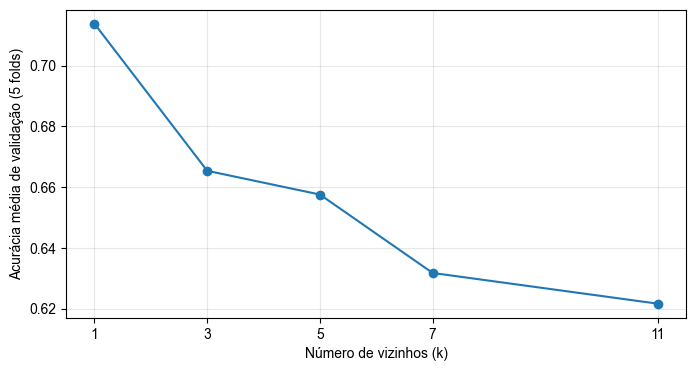

In [12]:
from sklearn.model_selection import cross_val_score
from imblearn.pipeline import make_pipeline
valores_k = [1, 3, 5, 7, 11]
acuracias_medias = []

for k in valores_k:
    knn = make_pipeline(
        StandardScaler(),
        SMOTE(k_neighbors=3, random_state=42),
        KNeighborsClassifier(n_neighbors=k)
    )
    
    scores = cross_val_score(knn, X_train, y_train, cv=5, scoring='accuracy')
    
    media = scores.mean()
    acuracias_medias.append(media)
    print(f"k = {k:2d} | Acurácia Média no CV (5 folds): {media:.4f}")

melhor_k = valores_k[np.argmax(acuracias_medias)]
print(f"\nO melhor valor de k encontrado foi: {melhor_k}")

plt.plot(valores_k, acuracias_medias, marker="o")
plt.xlabel("Número de vizinhos (k)")
plt.ylabel("Acurácia média de validação (5 folds)")
plt.xticks(valores_k)
plt.grid(alpha=0.3)
plt.show()

### Resposta — item 3

Entre os valores avaliados, **k = 1** obteve a maior acurácia média de validação cruzada: **71,38%**. Por isso foi escolhido para o modelo final. O risco de overfitting com poucos vizinhos não impede essa escolha: o critério utilizado foi o desempenho na validação, e não a acurácia de treino. Para valores muito baixos de k, o modelo é mais sensível ao ruído e pode apresentar overfitting. Para valores muito altos, a decisão fica excessivamente suavizada e pode ocorrer underfitting.

## 4. Avaliação do modelo

Utilizando o conjunto de teste, calcule a matriz de confusão e as métricas de acurácia, precisão, recall e F1-score para cada classe. Responda: entre quais classes o modelo erra com mais frequência?

In [13]:
knn = make_pipeline(
    StandardScaler(),
    SMOTE(k_neighbors=3, random_state=42),
    KNeighborsClassifier(n_neighbors=melhor_k)
)
knn.fit(X_train, y_train)

y_prev = knn.predict(X_test)

metricas = classification_report(y_test, y_prev)
print("\nMétricas por Classe:")
print(metricas)


Métricas por Classe:
              precision    recall  f1-score   support

           0       0.71      0.73      0.72       149
           1       0.75      0.72      0.73       167
           2       0.20      0.25      0.22         4

    accuracy                           0.72       320
   macro avg       0.55      0.57      0.56       320
weighted avg       0.72      0.72      0.72       320



In [14]:
print(confusion_matrix(y_test, y_prev))
print(f"Acurácia: {accuracy_score(y_test, y_prev):.4f}")

[[109  39   1]
 [ 44 120   3]
 [  1   2   1]]
Acurácia: 0.7188


### Resposta — item 4

Os erros mais frequentes ocorreram entre as classes **ruim (0)** e **médio (1)**: 39 vinhos ruins foram classificados como médios e 44 médios como ruins, totalizando 83 confusões entre essas duas classes.

A acurácia final foi **71,88%**, mas a classe bom teve precisão de 20%, recall de 25% e F1 de aproximadamente 22%. Dos quatro vinhos bons presentes no teste, apenas um foi classificado corretamente. Portanto, a acurácia global não representa bem o desempenho nessa classe rara(deve ter sido inventada pelos os avaliadores).

In [15]:
# Mesmo resultado com o scikit-learn
from sklearn.decomposition import PCA

Xp = scaler.transform(X)
pca = PCA(n_components=2)
Z_sk = pca.fit_transform(Xp)

print("Variância explicada:", np.round(pca.explained_variance_ratio_, 4))
print("Acumulada: %.1f%%" % (pca.explained_variance_ratio_.sum() * 100))

Variância explicada: [0.276  0.1739]
Acumulada: 45.0%


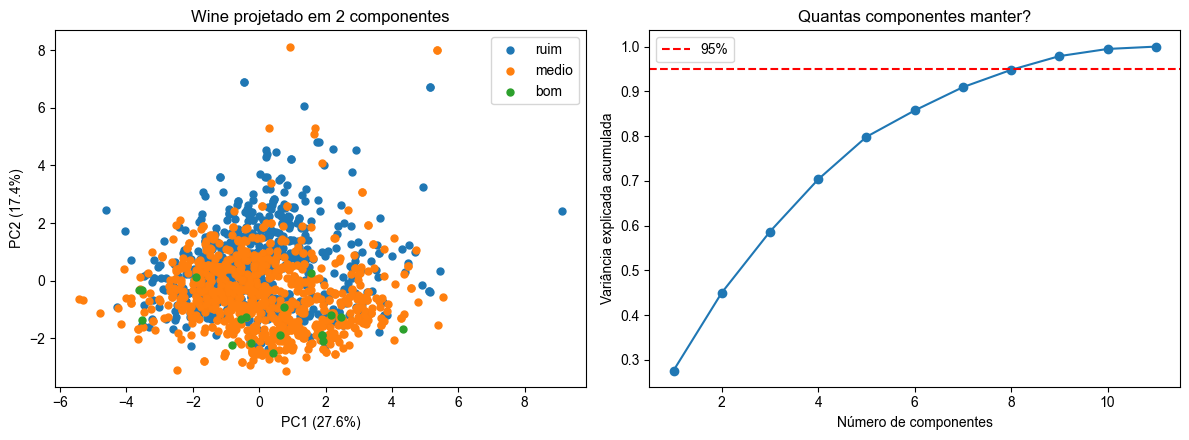

Componentes necessárias para 95%% da variância: 9 (de 11)


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# (a) projeção nas duas primeiras componentes
for classe, nome in enumerate(['ruim', 'medio', 'bom']):
    m = y == classe
    ax[0].scatter(Z_sk[m, 0], Z_sk[m, 1], label=nome, s=25)
ax[0].set_xlabel("PC1 (%.1f%%)" % (pca.explained_variance_ratio_[0] * 100))
ax[0].set_ylabel("PC2 (%.1f%%)" % (pca.explained_variance_ratio_[1] * 100))
ax[0].set_title("Wine projetado em 2 componentes")
ax[0].legend()

# (b) variância explicada acumulada (scree plot)
pca_full = PCA().fit(Xp)
acum = np.cumsum(pca_full.explained_variance_ratio_)
ax[1].plot(range(1, len(acum) + 1), acum, marker="o")
ax[1].axhline(0.95, color="r", linestyle="--", label="95%")
ax[1].set_xlabel("Número de componentes")
ax[1].set_ylabel("Variância explicada acumulada")
ax[1].set_title("Quantas componentes manter?")
ax[1].legend()

for a in ax:
    a.grid(False)
plt.tight_layout()
plt.show()

k95 = np.argmax(acum >= 0.95) + 1
print(f"Componentes necessárias para 95%% da variância: {k95} (de {Xp.shape[1]})")

In [20]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from sklearn.decomposition import PCA

# 1. Configurar o PCA para 3 componentes
pca = PCA(n_components=3)
Z_sk = pca.fit_transform(Xp)

# 2. Criar a figura 3D
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# 3. Plotar os dados
for classe, nome in enumerate(['ruim', 'medio', 'bom']):
    m = y == classe
    ax.scatter(Z_sk[m, 0], Z_sk[m, 1], Z_sk[m, 2], label=nome, s=25)

ax.set_xlabel("PC1 (%.1f%%)" % (pca.explained_variance_ratio_[0] * 100))
ax.set_ylabel("PC2 (%.1f%%)" % (pca.explained_variance_ratio_[1] * 100))
ax.set_zlabel("PC3 (%.1f%%)" % (pca.explained_variance_ratio_[2] * 100))
ax.set_title("Wine projetado em 3 componentes - Visão Rotacional")
ax.legend()

# 4. Função de atualização para a animação
def atualizar_angulo(angulo):
    # elev = inclinação vertical, azim = rotação horizontal
    ax.view_init(elev=20, azim=angulo)

# 5. Criar a animação (gira de 0 a 360 graus, de 2 em 2)
ani = FuncAnimation(fig, atualizar_angulo, frames=range(0, 360, 10), interval=50)

# Fechar a figura estática para não duplicar o plot na tela
plt.close(fig)

# 6. Exibir a animação interativa no Jupyter Notebook
HTML(ani.to_jshtml())